WEEK 7

**DIMENSIONALITY REDUCTION**

TEAM 16

Loading and the Dataset




In [2]:

from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:

import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if 'chicago_scaled' in file.lower():
            print(os.path.join(root, file))


/content/drive/MyDrive/chicago_scaled.csv


In [4]:

import pandas as pd

file_path = '/content/drive/MyDrive/chicago_scaled.csv'

df = pd.read_csv(file_path)




/tmp/ipykernel_10459/1112462977.py:5: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


 Dataset Inspection and Feature Preparation

---



The Week 6 scaled dataset is loaded to inspect its dimensions, column names, data types, and missing values. This step helps identify suitable numerical features for feature selection and Principal Component Analysis (PCA). Identifier columns, raw text columns, and redundant representations of the same features will be considered separately to ensure that the selected features are appropriate for further analysis.

In [5]:


print("Dataset shape:", df.shape)

print("\nColumn data types:")
print(df.dtypes)



print("\nNumerical columns:")
print(df.select_dtypes(include='number').columns.tolist())


Dataset shape: (8422096, 35)

Column data types:
ID                        int64
Case Number              object
Date                     object
Block                    object
IUCR                     object
Primary Type             object
Description              object
Location Description     object
Arrest                     bool
Domestic                   bool
Beat                      int64
District                float64
Ward                    float64
Community Area          float64
FBI Code                 object
X Coordinate            float64
Y Coordinate            float64
Year                      int64
Updated On               object
Latitude                float64
Longitude               float64
Location                 object
Hour                      int64
Month                     int64
Day                       int64
Hour_MinMax             float64
Month_MinMax            float64
Day_MinMax              float64
X_ZScore                float64
Y_ZScore               

 Variance Thresholding

---



Variance Thresholding is a feature-selection technique that identifies features with low variance. Features with little variation may contribute limited information to an analysis. The variance of suitable numerical features will be calculated and compared to identify potentially low-variance features.

In [6]:

import pandas as pd
from sklearn.feature_selection import VarianceThreshold

# Select suitable features on comparable 0–1 scales
features = [
    'Hour_MinMax',
    'Month_MinMax',
    'Day_MinMax',
    'Arrest',
    'Domestic'
]

X_var = df[features].copy()

# Convert Boolean columns to numeric values
for col in ['Arrest', 'Domestic']:
    X_var[col] = X_var[col].map({True: 1, False: 0}).fillna(
        X_var[col].mode().iloc[0] if not X_var[col].mode().empty else 0
    )

# Fill missing scaled values with their median
for col in ['Hour_MinMax', 'Month_MinMax', 'Day_MinMax']:
    X_var[col] = X_var[col].fillna(X_var[col].median())

# Display variance of each feature
variance_values = X_var.var()
print("Variance of each feature:")
print(variance_values.sort_values())

# Apply a small illustrative variance threshold
threshold = 0.01
selector = VarianceThreshold(threshold=threshold)
selector.fit(X_var)

results = pd.DataFrame({
    'Feature': features,
    'Variance': selector.variances_,
    'Decision': [
        'Retain' if selected else 'Low variance'
        for selected in selector.get_support()
    ]
})

print("\nVariance Thresholding Results:")
print(results.to_string(index=False))


Variance of each feature:
Hour_MinMax     0.086408
Day_MinMax      0.086958
Month_MinMax    0.092102
Domestic        0.142820
Arrest          0.188650
dtype: float64

Variance Thresholding Results:
     Feature  Variance Decision
 Hour_MinMax  0.086408   Retain
Month_MinMax  0.092102   Retain
  Day_MinMax  0.086958   Retain
      Arrest  0.188650   Retain
    Domestic  0.142820   Retain


 Correlation-Based Feature Selection

---



Correlation-Based Feature Selection is used to measure the strength and direction of relationships between numerical features. In this project, a correlation matrix and heatmap are used to examine the relationships among Hour_MinMax, Month_MinMax, Day_MinMax, Arrest, and Domestic. Highly correlated features may contain overlapping information, so this analysis helps identify potentially redundant features before applying Principal Component Analysis (PCA).

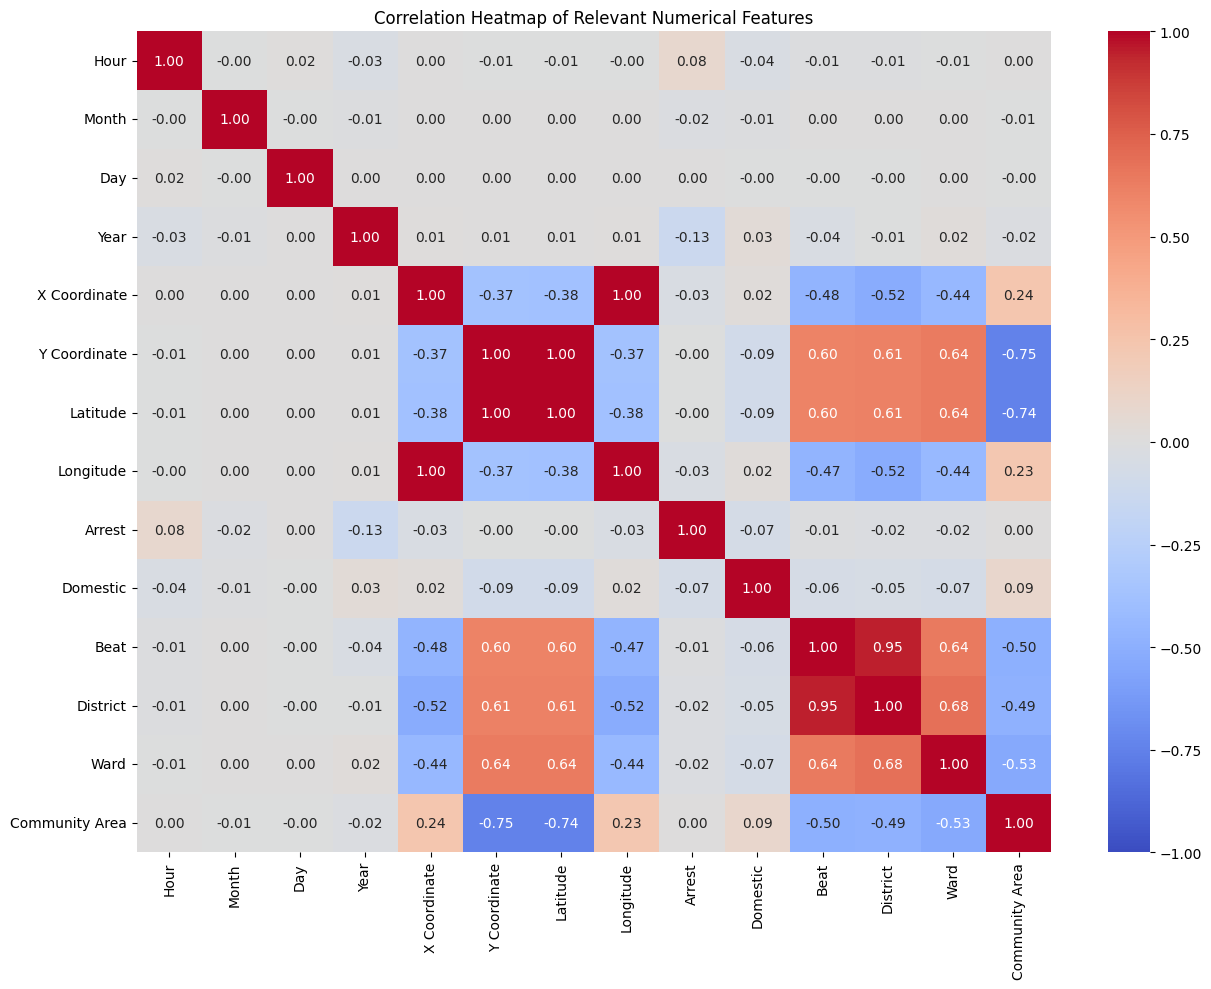

Strongly correlated pairs (absolute correlation >= 0.80):
   Feature 1 Feature 2  Correlation  Absolute Correlation
Y Coordinate  Latitude     0.999993              0.999993
X Coordinate Longitude     0.999764              0.999764
        Beat  District     0.951934              0.951934


In [7]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Select relevant original features (exclude IDs and duplicate scaled versions)
numeric_cols = [
    'Hour', 'Month', 'Day', 'Year',
    'X Coordinate', 'Y Coordinate',
    'Latitude', 'Longitude',
    'Arrest', 'Domestic',
    'Beat', 'District', 'Ward', 'Community Area'
]

# Use a random sample to make analysis faster on 8.4 million rows
sample_df = df[numeric_cols].sample(
    n=min(500000, len(df)),
    random_state=42
).copy()

# Convert selected columns to numeric where needed
for col in numeric_cols:
    sample_df[col] = pd.to_numeric(sample_df[col], errors='coerce')

# Calculate pairwise correlations
correlation_matrix = sample_df.corr()

# Display the heatmap
plt.figure(figsize=(13, 10))
sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    annot=True,
    fmt='.2f'
)
plt.title('Correlation Heatmap of Relevant Numerical Features')
plt.tight_layout()
plt.show()

# List strongly correlated pairs, excluding self-correlations
upper = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

pairs = upper.stack().reset_index()
pairs.columns = ['Feature 1', 'Feature 2', 'Correlation']
pairs['Absolute Correlation'] = pairs['Correlation'].abs()

print("Strongly correlated pairs (absolute correlation >= 0.80):")
print(
    pairs[pairs['Absolute Correlation'] >= 0.80]
    .sort_values('Absolute Correlation', ascending=False)
    .to_string(index=False)
)


Mitigating Multicollinearity

---



Multicollinearity occurs when two or more features are strongly related to one another. It can cause problems when interpreting the individual effects of features in regression models. In this project, correlation analysis is used to identify redundant features and select suitable representations for further dimensionality reduction. Unnecessary duplicate representations are avoided while preserving meaningful information for crime analysis.

In [7]:

import numpy as np
import pandas as pd

# Identify highly correlated feature pairs
threshold = 0.80

upper = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = upper.stack().reset_index()
high_corr_pairs.columns = ['Feature 1', 'Feature 2', 'Correlation']

high_corr_pairs = high_corr_pairs[
    high_corr_pairs['Correlation'].abs() >= threshold
].sort_values(
    'Correlation',
    key=lambda values: values.abs(),
    ascending=False
)

print("Highly correlated feature pairs:")
if high_corr_pairs.empty:
    print("No pairs exceeded the threshold.")
else:
    print(high_corr_pairs.to_string(index=False))

# Create a proposed list of features to exclude
# Keep the first feature in each pair by default.
# Review the feature meanings before accepting these suggestions.
features_to_exclude = set(high_corr_pairs['Feature 2'])

print("\nFeatures flagged for review:")
if features_to_exclude:
    print(sorted(features_to_exclude))
else:
    print("No features flagged by the correlation threshold.")


Highly correlated feature pairs:
   Feature 1 Feature 2  Correlation
Y Coordinate  Latitude     0.999993
X Coordinate Longitude     0.999764
        Beat  District     0.951934

Features flagged for review:
['District', 'Latitude', 'Longitude']


Result of collinearity mitigation

---



In [8]:

# Step 4: Finalize the initial candidate feature set for PCA

pca_features = [
    'Hour', 'Month', 'Day', 'Year',
    'X Coordinate', 'Y Coordinate'
]

print("Selected PCA candidate features:")
print(pca_features)

print("\nExcluded from this PCA experiment:")
print([
    'Latitude', 'Longitude',  # duplicate geographic representation
    'Beat', 'District'        # administrative codes
])


Selected PCA candidate features:
['Hour', 'Month', 'Day', 'Year', 'X Coordinate', 'Y Coordinate']

Excluded from this PCA experiment:
['Latitude', 'Longitude', 'Beat', 'District']


 Introduction to PCA and Data Preparation

Principal Component Analysis (PCA) is a dimensionality-reduction technique that transforms a set of numerical features into a smaller set of new features called principal components. These components capture as much of the variation in the original data as possible.

In [9]:

import pandas as pd
from sklearn.preprocessing import StandardScaler

# Select one representation for each feature
pca_columns = [
    'Hour_MinMax',
    'Month_MinMax',
    'Day_MinMax',
    'Year',
    'X_ZScore',
    'Y_ZScore'
]

# Create a separate PCA dataset
pca_data = df[pca_columns].copy()

# Rename columns for easier interpretation
pca_data.columns = [
    'Hour', 'Month', 'Day', 'Year', 'X_Coordinate', 'Y_Coordinate'
]

# Remove rows with missing values
pca_data = pca_data.dropna()

# Exclude invalid zero coordinates
pca_data = pca_data[
    (pca_data['X_Coordinate'] != 0) &
    (pca_data['Y_Coordinate'] != 0)
].copy()

# Standardize Year only; the other features are already scaled
year_scaler = StandardScaler()
pca_data['Year'] = year_scaler.fit_transform(
    pca_data[['Year']]
).ravel()

print("Prepared PCA dataset shape:", pca_data.shape)
print("\nMissing values:")
print(pca_data.isnull().sum())

print("\nFeature summary:")
print(pca_data.describe().round(3))


Prepared PCA dataset shape: (8328252, 6)

Missing values:
Hour            0
Month           0
Day             0
Year            0
X_Coordinate    0
Y_Coordinate    0
dtype: int64

Feature summary:
              Hour        Month          Day         Year  X_Coordinate  \
count  8328252.000  8328252.000  8328252.000  8328252.000   8328252.000   
mean         0.570        0.504        0.488       -0.000        -0.000   
std          0.294        0.303        0.295        1.000         1.000   
min          0.000        0.000        0.000       -1.415       -68.701   
25%          0.391        0.273        0.233       -0.849        -0.683   
50%          0.609        0.545        0.500       -0.141         0.092   
75%          0.826        0.727        0.733        0.849         0.693   
max          1.000        1.000        1.000        1.981         2.387   

       Y_Coordinate  
count   8328252.000  
mean         -0.000  
std           1.000  
min         -58.151  
25%          -0.8

Principal Component Analysis (PCA)

---



It is applied to the selected scaled temporal and geographical features to transform them into principal components. These components are ordered according to the amount of variance they explain.

In [10]:

import numpy as np
import pandas as pd
from sklearn.decomposition import IncrementalPCA

# Select original coordinates and existing scaled features
pca_columns = [
    'Hour_MinMax', 'Month_MinMax', 'Day_MinMax',
    'Year', 'X_ZScore', 'Y_ZScore'
]

# Validate locations using ORIGINAL coordinates
valid_locations = (
    df['X Coordinate'].notna() &
    df['Y Coordinate'].notna() &
    (df['X Coordinate'] > 0) &
    (df['Y Coordinate'] > 0)
)

# Prepare a clean PCA dataset
pca_data = df.loc[valid_locations, pca_columns].copy()
pca_data.columns = [
    'Hour', 'Month', 'Day', 'Year', 'X_Coordinate', 'Y_Coordinate'
]

# Remove any remaining missing values
pca_data = pca_data.dropna()

# Standardize Year
from sklearn.preprocessing import StandardScaler

year_scaler = StandardScaler()
pca_data['Year'] = year_scaler.fit_transform(
    pca_data[['Year']]
).ravel()

print("Rows available for PCA:", len(pca_data))
print("Missing values:", pca_data.isnull().sum().sum())

# Fit Incremental PCA in batches
n_components = 6
batch_size = 100_000

ipca = IncrementalPCA(
    n_components=n_components,
    batch_size=batch_size
)

for start in range(0, len(pca_data), batch_size):
    batch = pca_data.iloc[start:start + batch_size]
    if len(batch) >= n_components:
        ipca.partial_fit(batch)

print("\nPCA fitting completed.")

print("\nExplained variance ratio:")
for i, ratio in enumerate(ipca.explained_variance_ratio_, start=1):
    print(f"PC{i}: {ratio:.4%}")

print(
    "\nTotal variance explained:",
    f"{ipca.explained_variance_ratio_.sum():.4%}"
)


Rows available for PCA: 8328103
Missing values: 0

PCA fitting completed.

Explained variance ratio:
PC1: 46.2143%
PC2: 32.0667%
PC3: 13.2339%
PC4: 2.9455%
PC5: 2.8073%
PC6: 2.7323%

Total variance explained: 100.0000%


Visualizing Explained Variance

---


 **Purpose**:Visualize how much variance each principal component captures and how much information is retained when multiple components are combined.

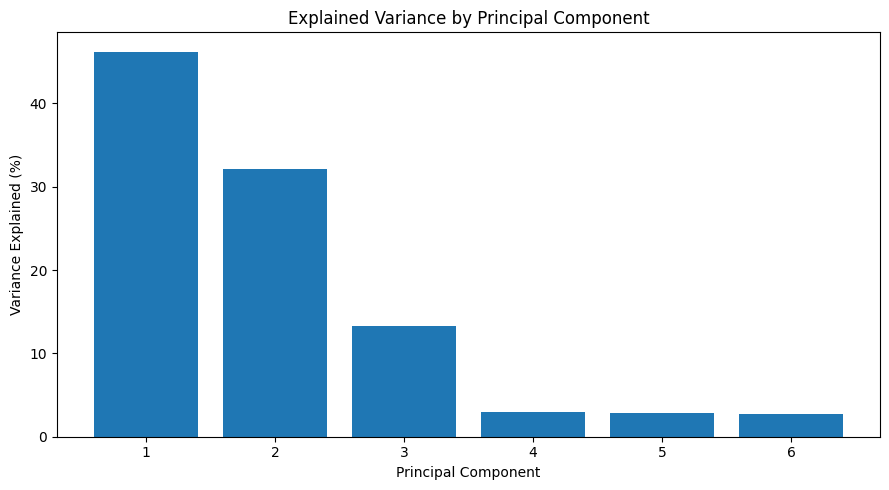

In [12]:

import matplotlib.pyplot as plt
import numpy as np

# Explained variance from the fitted Incremental PCA
explained_variance = ipca.explained_variance_ratio_
components = np.arange(1, len(explained_variance) + 1)

plt.figure(figsize=(9, 5))
plt.bar(components, explained_variance * 100)

plt.title('Explained Variance by Principal Component')
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained (%)')
plt.xticks(components)
plt.tight_layout()
plt.show()


Cumulative explained variance

---



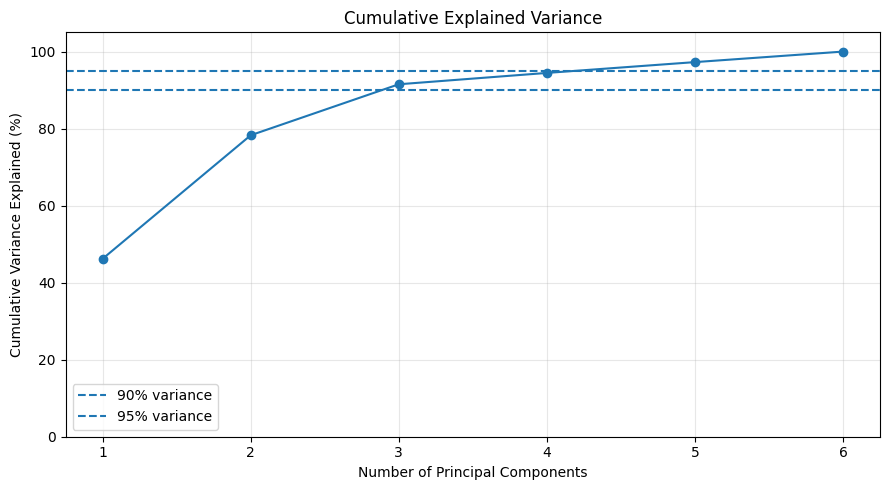

Cumulative explained variance:
First 1 component(s): 46.2143%
First 2 component(s): 78.2810%
First 3 component(s): 91.5149%
First 4 component(s): 94.4604%
First 5 component(s): 97.2677%
First 6 component(s): 100.0000%


In [13]:

cumulative_variance = np.cumsum(explained_variance) * 100

plt.figure(figsize=(9, 5))
plt.plot(components, cumulative_variance, marker='o')

plt.axhline(y=90, linestyle='--', label='90% variance')
plt.axhline(y=95, linestyle='--', label='95% variance')

plt.title('Cumulative Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Variance Explained (%)')
plt.xticks(components)
plt.ylim(0, 105)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Cumulative explained variance:")
for i, value in enumerate(cumulative_variance, start=1):
    print(f"First {i} component(s): {value:.4f}%")


 Two-Dimensional PCA Visualization

---



A two-dimensional scatter plot is created using the first two principal components obtained from PCA. Each point represents a crime incident in the reduced feature space. This visualization provides a compact representation of the dataset and helps explore patterns and groupings in the transformed features. The first two components explain approximately 78.28% of the variance in the selected features.

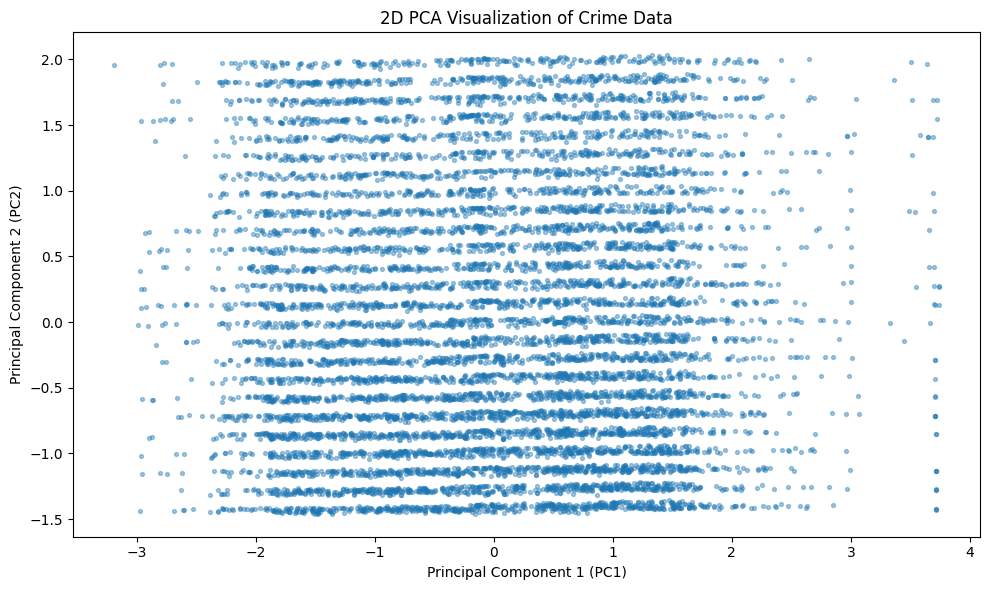

In [14]:

import matplotlib.pyplot as plt
import pandas as pd

# Transform the prepared dataset using the fitted PCA model
pca_scores = ipca.transform(pca_data)

# Store the first two principal components
pca_results = pd.DataFrame({
    'PC1': pca_scores[:, 0],
    'PC2': pca_scores[:, 1]
})

# Sample observations for visualization
plot_data = pca_results.sample(
    n=min(10000, len(pca_results)),
    random_state=42
)

# Create scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(
    plot_data['PC1'],
    plot_data['PC2'],
    alpha=0.4,
    s=8
)

plt.title('2D PCA Visualization of Crime Data')
plt.xlabel('Principal Component 1 (PC1)')
plt.ylabel('Principal Component 2 (PC2)')
plt.tight_layout()
plt.show()




### Conclusion :

The two-dimensional PCA scatter plot represents crime incidents using the first two principal components. Together, these components explain approximately 78.28% of the variance in the selected features. The visualization provides a reduced-dimensional view of the data and supports exploratory analysis of patterns in the selected temporal and geographical variables. Actual geographical hotspots will continue to be interpreted using the original coordinate data.


# Overall Conclusion — Week 7

---



Feature selection techniques, including Variance Thresholding, Correlation-Based Feature Selection, and Multicollinearity Analysis, were performed on the Chicago crime dataset. PCA was then applied to six selected features using Incremental PCA. The first two principal components explained approximately 78.28% of the variance, while the first three explained 91.51%. Explained variance plots and a 2D scatter plot were used to visualize the results and demonstrate dimensionality reduction.